# Understanding disordered structures

Many important materials in modern technology cannot be represented by a simple repeating unit cell — they have *disorder*.
For example:
- Solid-state electrolyte materials, like LLZO garnet, have a disordered Li sublattice. Sites can be either occupied by Li or vacant. 
- Electrode materials like disordered rocksalts (DRX) exhibit disorder on both the Li sublattice and among the framework cations. 
- Most alloys are disordered. High-entropy alloys in particular are defined by disorder.
- Oxygen-deficient materials like doped ceria or $\mathrm{SrFeO}_{3-\delta}$ can be represented with disordered O sublattices.
- Mixed-anion materials like oxyfluorides have sites shared by O and F. 

This notebook goes through some tools we can use to analyze, create, and manipulate disordered structures:

1. Load a disordered structure, see which sites are disordered, and check that the occupancies fit the unit cell
2. Count how many ordered configurations a disordered structure has
3. Use symmetry to find how many of those configurations are actually different
4. Edit occupancies to model substitutions and dopants

*Note*: this package is designed to handle substitutional and vacancy disorder on lattices, not completely amorphous materials like glasses. 

In [3]:
# Imports
import math
from pathlib import Path
import numpy as np
from pymatgen.core import Lattice, Structure

from disorderly import (
    configuration_degeneracy,
    count_configurations,
    count_distinct_configurations,
    describe_wyckoff_sites,
    disordered_site_groups,
    disordered_site_indices,
    enumerate_ordered_configurations,
    get_spacegroup,
    label_wyckoff_sites,
    random_ordered_configuration,
    replace_species_and_occupancy,
    set_site_occupancies,
    site_permutations,
    supercell_multiplier,
)

structures_dir = Path("../tests/test_structures")

## 1. Load a disordered structure

Pymatgen can read a disordered structure from a CIF file with the usual `Structure.from_file`. Partially occupied sites come through as sites with fractional species amounts.
Here, we load the structure for the cubic garnet Li7La3Zr2O12 (LLZO). The 24d tetrahedral sites and 48g octahedral sites in this structure are partially occupied by Li.

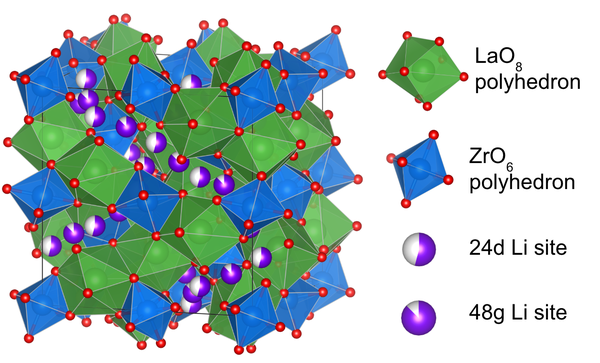

In [4]:
disordered_llzo = Structure.from_file(structures_dir / "cubic_LLZO.cif")

print(f"formula: {disordered_llzo.composition.formula}  ({disordered_llzo.composition.reduced_formula})")
print(f"space group: {get_spacegroup(disordered_llzo).symbol}")
print(f"sites in cell: {len(disordered_llzo)}")
print(f"disordered sites: {len(disordered_site_indices(disordered_llzo))}\n") # Counts how many sites have fractional occupancies

labelled = label_wyckoff_sites(disordered_llzo) # This returns a copy in which every site carries a "wyckoff" site property and a label such as "Li_24d"
#print(labelled)

formula: Li56 La24 Zr16 O96  (Li7La3Zr2O12)
space group: Ia-3d
sites in cell: 208
disordered sites: 72



In [5]:
# Summarize the structure one Wyckoff site at a time: which species sit there, how many sites there are in the cell,
# and (for disordered sites) what an ordered configuration places on them
print(describe_wyckoff_sites(disordered_llzo), '\n')

# To look at just the disordered sites, use disordered_site_groups
dsite_groups = disordered_site_groups(disordered_llzo)
print('Disordered sites:')
for group in dsite_groups:
    print(group.occupancies, group.counts)

Wyckoff sites for Li56 La24 Zr16 O96
label          species                        sites in cell   disordered?  ordered configuration
Li_24d         Li+:0.542                                 24   yes          13 Li+, 11 vacancy
Li_48g         Li+:0.896                                 48   yes          43 Li+, 5 vacancy
La_24c         La3+                                      24   no           -
Zr_16a         Zr4+                                      16   no           -
O_96h          O2-                                       96   no           - 

Disordered sites:
{Species Li+: 0.5416666666666666} {Species Li+: 13, None: 11}
{Species Li+: 0.8958333333333334} {Species Li+: 43, None: 5}


`disordered_site_groups` pools disordered sites that share the same species and occupancies, and converts each pool's occupancies into whole numbers of atoms and vacancies (the `counts` printed above). The last column of the `describe_wyckoff_sites` table comes from these counts.

To get a random ordered version of this structure, we can use `random_ordered_configuration`. You can see that the ordered structure has no fractional occupancies.

In [6]:
ordered = random_ordered_configuration(disordered_llzo, np.random.default_rng(0))
print(f"disordered sites: {len(disordered_site_indices(ordered))}\n") # Counts how many sites have fractional occupancies

disordered sites: 0



### When the occupancies don't fit the cell

An ordered configuration has a whole atom or a vacancy on every site, so each sublattice needs a whole number of each species. In LLZO that works out: 24 × 0.542 = 13 Li on the tetrahedral sites and 48 × 0.896 = 43 Li on the octahedral sites.

That isn't always true. Spinel Li4Ti5O12 (LTO) has 16 octahedral sites per unit cell, each shared by Li (occupancy 1/6) and Ti (5/6). That puts 16 × 1/6 = 2.67 Li on them, and no ordered structure can hold two-thirds of an atom. If we rounded to 3 Li, every ordered configuration would have the wrong composition.

`disordered_site_groups` checks for this and warns when it happens:

In [7]:
lto = Structure.from_file(structures_dir / "LTO_COD_1001098.cif")
print(f"formula: {lto.composition.formula}")
print(f"disordered sites: {len(disordered_site_indices(lto))}")

lto_groups = disordered_site_groups(lto) # Warns because 16 x 1/6 Li is not a whole number

formula: Li10.6672 Ti13.3328 O32
disordered sites: 16


/var/folders/lj/p54rcr957k7d3bwdk_m7yyc80000gn/T/ipykernel_62032/2187021684.py:5: UserWarning: Site occupancies are not whole numbers of atoms in this cell, so ordered configurations will not reproduce them exactly: 16 sites of Li+: 0.1667, Ti4+: 0.8333 hold Li+: 2.667, Ti4+: 13.333, rounded to Li+: 3, Ti4+: 13. Multiply the cell by 3 (any supercell with 3x as many sites, e.g. structure.make_supercell([3, 1, 1])) to make every count a whole number.
  lto_groups = disordered_site_groups(lto) # Warns because 16 x 1/6 Li is not a whole number


The fix is to use a *supercell*: several copies of the unit cell stacked together and treated as one larger cell. Three copies of the cell have 48 octahedral sites, and 48 × 1/6 = 8 Li is a whole number.

`supercell_multiplier` returns the smallest number of copies that works. Any supercell with that many times as many sites will do. Here we stack three cells along one axis (`[3, 1, 1]`) because it's the simplest. For real sampling, a supercell that is closer to the same length in every direction is usually better. In a 3×1×1 cell, every ordering repeats after one cell length along two directions but only after three along the third, which builds in a preferred direction that the real crystal doesn't have.

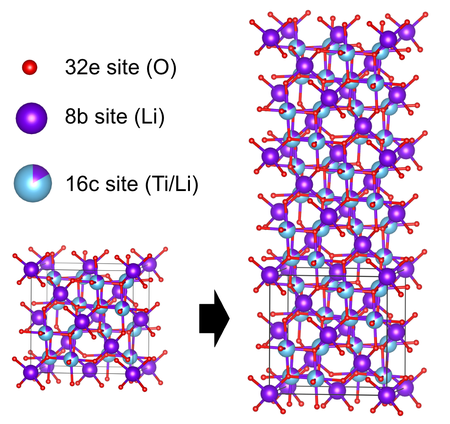

In [8]:
m = supercell_multiplier(lto)
print(f"multiply the LTO cell by {m}")

lto_super = lto.copy() # make_supercell modifies a structure in place, so work on a copy
lto_super.make_supercell([m, 1, 1])
print(f"supercell multiplier now: {supercell_multiplier(lto_super)}\n") # 1 means the occupancies now fit
print(describe_wyckoff_sites(lto_super))

multiply the LTO cell by 3
supercell multiplier now: 1

Wyckoff sites for Li32.0016 Ti39.9984 O96
label          species                        sites in cell   disordered?  ordered configuration
Li_8b          Li+                                       24   no           -
Li-Ti_16c      Li+:0.167, Ti4+:0.833                     48   yes          8 Li+, 40 Ti4+
O_32e          O2-                                       96   no           -


The mixed Li/Ti sites now hold exactly 8 Li and 40 Ti in every ordered configuration.

You may notice these sites are labelled 16c here, while the original cell file calls them 16d. They are the same positions. Spinel's space group allows more than one equally valid choice of origin, and spglib picked a different one for the supercell. That swaps the letters of Wyckoff sites with the same multiplicity.

## 2. How many ordered configurations are there?

In section 1, `random_ordered_configuration` picked one way to arrange the Li in LLZO. How many other choices could it have made?

Take the tetrahedral sites first. An ordered configuration puts 13 Li on 24 sites and leaves the other 11 empty, so counting configurations means counting the ways to choose which 13 sites get a Li:

$$\binom{24}{13} = \frac{24!}{13!\,11!}$$

When a sublattice holds more than two kinds of occupant (vacancies count as one kind), the same idea gives the multinomial coefficient. For $n$ sites holding $n_1, n_2, \ldots$ of each kind:

$$\binom{n}{n_1, n_2, \ldots} = \frac{n!}{n_1!\, n_2! \cdots}$$

The tetrahedral and octahedral sublattices are filled independently, so the total number of configurations is the product of the counts for each sublattice. `count_configurations` does this calculation for any structure:

In [9]:
tet = math.comb(24, 13) # Ways to place 13 Li on 24 tetrahedral sites
octa = math.comb(48, 43) # Ways to place 43 Li on 48 octahedral sites
total = count_configurations(disordered_llzo)

print(f"C(24, 13) = {tet:,}")
print(f"C(48, 43) = {octa:,}")
print(f"product   = {tet * octa:,}")
print(f"count_configurations(disordered_llzo) = {total:,}  (~10^{math.log10(total):.1f})")
print(f"LTO 3x1x1 supercell: {count_configurations(lto_super):,}")

C(24, 13) = 2,496,144
C(48, 43) = 1,712,304
product   = 4,274,157,355,776
count_configurations(disordered_llzo) = 4,274,157,355,776  (~10^12.6)
LTO 3x1x1 supercell: 377,348,994


That is about 4 trillion configurations for one unit cell of LLZO. Even at one millisecond per energy calculation, which is far faster than any DFT or machine-learned potential, it would take more than a century to evaluate them all. Larger supercells make the number grow even faster.

This is why we can't find the lowest-energy ordering by checking every configuration. Instead we *sample*:

- **Random sampling** generates many random configurations, like the one in section 1, and keeps the lowest-energy ones.
- **Monte Carlo (MC)** starts from one configuration and repeatedly tries small changes, such as swapping a Li with a vacancy. Changes that lower the energy are always kept, and changes that raise it are sometimes kept, so the simulation drifts toward low-energy configurations without getting stuck in the first one it finds.

Those workflows are covered in `02_random_sampling_walkthrough.ipynb` and `03_simple_MC_example.ipynb`. The rest of this notebook looks at how many of these configurations are actually different.

## 3. Symmetry: many configurations are the same structure

A *symmetry operation* of a crystal is a rotation, reflection, inversion, or translation that maps the crystal onto itself. Apply one to an ordered configuration and the atoms end up on different sites, but the result is the same structure, just rotated or shifted. It has the same energy and the same properties, so it isn't really a new configuration.

A small example shows the idea. Put 2 atoms on the 4 corners of a square. There are $\binom{4}{2} = 6$ ways to do it, but only two different structures:

- **Adjacent corners:** 4 arrangements, all related by rotating the square.
- **Opposite corners:** 2 arrangements, related by a 90° rotation.

So the 6 configurations are really just 2 distinct structures. The number of configurations that are copies of a given structure is called its *degeneracy*: 4 for the adjacent-corner structure and 2 for the opposite-corner one.

Crystals have far more symmetry operations than a square, so most of the configurations counted in section 2 are copies of each other. Two functions handle the bookkeeping:

- `count_distinct_configurations` counts how many different structures there are.
- `configuration_degeneracy` tells you how many copies of a given configuration there are.

We'll start with the LTO supercell from section 1.

In [10]:
lto_perms = site_permutations(lto_super) # Find the symmetry operations once so both functions below can reuse them

lto_total = count_configurations(lto_super)
lto_distinct = count_distinct_configurations(lto_super, perms=lto_perms)

print(f"total configurations:    {lto_total:,}")
print(f"symmetrically distinct:  {lto_distinct:,}")

total configurations:    377,348,994
symmetrically distinct:  1,972,317


Only about 2 million of the 377 million configurations are different structures. On average, each distinct structure appears about 190 times in the full count.

Degeneracy matters when you compare energies. If two distinct structures have the same energy but one has twice as many copies, it is twice as likely to be found at equilibrium.

<details>
<summary>The math: symmetry groups, degeneracy, and Burnside's lemma</summary>

**The symmetry group.** `site_permutations` turns each symmetry operation of the disordered parent into a permutation of site indices: a list saying which site each site moves to. This includes the lattice translations within the cell. Together these permutations form the symmetry group $G$, and $|G|$ is the number of operations in it.

For the LTO supercell, $|G| = 192$, the same as for the original LTO cell. The supercell has 3 times as many lattice translations (12 instead of 4), but only operations that map the supercell onto itself count. Because the cell is three times longer in one direction, only 16 of the 48 cubic rotations survive, so $|G| = 12 \times 16 = 192$, the same as $4 \times 48$.

**Degeneracy.** The set of configurations related to a given one by symmetry is called its *orbit*, and the degeneracy $g$ is the orbit's size. If $k$ operations leave a configuration unchanged (including the identity), then $g = |G| / k$. For the square, the opposite-corner structure is unchanged by the identity and the 180° rotation, so $g = 4/2 = 2$.

In statistical mechanics, each distinct structure $i$ is weighted by $g_i e^{-E_i / k_B T}$.

**Counting distinct structures.** If every configuration had the full degeneracy $|G|$, the number of distinct structures would be $N_\text{total} / |G|$. Symmetric configurations have smaller orbits, which can only add to the count. `count_distinct_configurations` counts orbits exactly using Burnside's lemma:

$$N_\text{distinct} = \frac{1}{|G|} \sum_{g \in G} |\text{Fix}(g)|$$

where $\text{Fix}(g)$ is the set of configurations that operation $g$ leaves unchanged. A configuration is unchanged by $g$ only if every cycle of $g$'s site permutation is filled with a single kind of occupant, so $|\text{Fix}(g)|$ can be calculated from the cycle lengths without listing any configurations.

For the square, the identity fixes all 6 arrangements, the 180° rotation fixes the 2 opposite-corner ones, and the two 90° rotations fix none, so $N_\text{distinct} = (6 + 2 + 0 + 0)/4 = 2$.

Since the identity fixes every configuration, $N_\text{distinct} \geq N_\text{total} / |G|$, with equality only when no other operation fixes any configuration. For the LTO supercell, $N_\text{total} / |G| = 377{,}348{,}994 / 192 \approx 1{,}965{,}359$, while $N_\text{distinct} = 1{,}972{,}317$. The roughly 7,000 extra orbits come from symmetric configurations. For LLZO below, the two numbers are exactly equal, so no LLZO configuration in that cell is symmetric.

</details>

### LLZO

The same functions work for LLZO:

In [11]:
perms = site_permutations(disordered_llzo)
distinct = count_distinct_configurations(disordered_llzo, perms=perms)

print(f"total configurations:    {total:,}")
print(f"symmetrically distinct:  {distinct:,}")


total configurations:    4,274,157,355,776
symmetrically distinct:  44,522,472,456


The 4 trillion configurations reduce to about 45 billion distinct structures, exactly 96 times fewer. Unlike LTO, no LLZO configuration in this cell is more symmetric than the rest, so every distinct structure appears exactly 96 times: every configuration has a degeneracy of 96.

### Checking the count by listing every structure

`count_distinct_configurations` never lists the configurations, so it's worth checking it against a method that does. `enumerate_ordered_configurations` uses [icet](https://icet.materialsmodeling.org/), a separate package, to list one example of every distinct structure. icet finds the symmetry and removes duplicates with its own algorithm, without `site_permutations` or Burnside's lemma, so this is an independent check.

Listing only works for small cells. Rock-salt LiFeO2 in a 1×1×2 supercell has 8 cation sites shared by 4 Li and 4 Fe, which gives $\binom{8}{4} = 70$ configurations. The number of structures icet lists should match `count_distinct_configurations`. Their degeneracies should also add back up to 70, since every configuration is a copy of exactly one distinct structure.

icet is an optional dependency. If it isn't installed, the next cell stops and explains how to install it.

In [12]:
try:
    import icet  # noqa: F401 (only checking that it is installed)
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "This check needs icet, an optional dependency that lists every distinct structure independently "
        "of count_distinct_configurations. Install it with pip install \"disorderly[icet]\" "
        "(or pip install -e \".[icet]\" from the repository) and restart the kernel. "
        "You can also skip this cell: the rest of the notebook doesn't use icet."
    ) from None

rock_salt = Structure.from_spacegroup(
    "Fm-3m", Lattice.cubic(4.158), [{"Li+": 0.5, "Fe3+": 0.5}, "O2-"], [[0, 0, 0], [0.5, 0.5, 0.5]]
)
rock_salt.make_supercell([1, 1, 2])
rs_perms = site_permutations(rock_salt)

listed = list(enumerate_ordered_configurations(rock_salt)) # One example of each distinct structure, found by icet
degeneracies = [configuration_degeneracy(rock_salt, structure, perms=rs_perms) for structure in listed]

print(f"total configurations:           {count_configurations(rock_salt)}")
print(f"count_distinct_configurations:  {count_distinct_configurations(rock_salt, perms=rs_perms)}")
print(f"structures listed by icet:      {len(listed)}")
print(f"their degeneracies: {sorted(degeneracies)}, sum = {sum(degeneracies)}")

total configurations:           70
count_distinct_configurations:  8
structures listed by icet:      8
their degeneracies: [2, 4, 4, 4, 8, 8, 8, 32], sum = 70


## 4. Editing occupancies

Often the structure you want to study isn't exactly the one in your CIF file. You might want to swap in a different element, lower the Li content, or add a dopant. Two functions edit a disordered structure, and each returns a modified copy:

- `replace_species_and_occupancy` replaces one species with another wherever it occurs. You can limit it to sites where that species has a particular occupancy. Other species on the same sites are left alone.
- `set_site_occupancies` overwrites everything on the sites you choose. It is the tool to use for adding a dopant or changing several occupancies at once.

Ionic crystals need to be charge neutral: the oxidation states, weighted by occupancy, must add up to zero. `Structure.charge` adds them up, so it is a quick way to check an edit.

### Substitute a species

Replacing every Li+ with Na+ gives the sodium analogue of LLZO. Both ions are +1, so the structure stays neutral.

In [13]:
na_llzo = replace_species_and_occupancy(disordered_llzo, "Li+", "Na+")
print(f"{na_llzo.composition.reduced_formula}, charge {na_llzo.charge:+.2f}")

Na7La3Zr2O12, charge +0.00


### Change the occupancy of one sublattice

To remove one Li from the tetrahedral sites, replace Li with Li at a lower occupancy. `target_occupancy=13/24` limits the change to the tetrahedral sites, and `new_occupancy=12/24` leaves 12 Li on them.

Taking away a Li+ leaves the cell with a charge of −1. In a real material that charge would have to be balanced by another change, such as the dopant in the next example.

In [14]:
li_poor = replace_species_and_occupancy(disordered_llzo, "Li+", "Li+", target_occupancy=13 / 24, new_occupancy=12 / 24)
print(f"{(li_poor.composition / 8).formula} per formula unit, charge {li_poor.charge:+.2f} per cell\n") # The cell holds 8 formula units
print(describe_wyckoff_sites(li_poor))

Li6.875 La3 Zr2 O12 per formula unit, charge -1.00 per cell

Wyckoff sites for Li55 La24 Zr16 O96
label          species                        sites in cell   disordered?  ordered configuration
Li_24d         Li+:0.5                                   24   yes          12 Li+, 12 vacancy
Li_48g         Li+:0.896                                 48   yes          43 Li+, 5 vacancy
La_24c         La3+                                      24   no           -
Zr_16a         Zr4+                                      16   no           -
O_96h          O2-                                       96   no           -


### Add a dopant

Ga is a common dopant in LLZO. Ga3+ sits on the tetrahedral Li sites, and since one Ga3+ carries the charge of three Li+, each Ga added removes three Li. This is called an *aliovalent* substitution: the new ion has a different charge from the one it replaces, and vacancies make up the difference.

Li6.25Ga0.25La3Zr2O12 has 2 Ga and 50 Li per unit cell (8 formula units). Keeping the 43 octahedral Li, the 24 tetrahedral sites hold 7 Li, 2 Ga, and 15 vacancies. We select the tetrahedral sites using the Wyckoff labels from section 1, then set their occupancies:

In [15]:
tetrahedral = [i for i, site in enumerate(labelled) if site.label == "Li_24d"] # Indices of the 24 tetrahedral sites
ga_llzo = set_site_occupancies(disordered_llzo, tetrahedral, {"Li+": 7 / 24, "Ga3+": 2 / 24}) # The remaining 15/24 is vacant

print(f"{(ga_llzo.composition / 8).formula} per formula unit, charge {ga_llzo.charge:+.2f} per cell\n")
print(describe_wyckoff_sites(ga_llzo))

ga_total = count_configurations(ga_llzo)
print(f"\nconfigurations: {ga_total:,} = 24!/(7! 2! 15!) x C(48, 43) = "
      f"{math.factorial(24) // (math.factorial(7) * math.factorial(2) * math.factorial(15)) * math.comb(48, 43):,}")
print(f"symmetrically distinct: {count_distinct_configurations(ga_llzo, perms=perms):,}")

Li6.25 La3 Zr2 Ga0.25 O12 per formula unit, charge +0.00 per cell

Wyckoff sites for Li50 La24 Zr16 Ga2 O96
label          species                        sites in cell   disordered?  ordered configuration
Ga-Li_24d      Li+:0.292, Ga3+:0.0833                    24   yes          2 Ga3+, 7 Li+, 15 vacancy
Li_48g         Li+:0.896                                 48   yes          43 Li+, 5 vacancy
La_24c         La3+                                      24   no           -
Zr_16a         Zr4+                                      16   no           -
O_96h          O2-                                       96   no           -

configurations: 80,598,395,851,776 = 24!/(7! 2! 15!) x C(48, 43) = 80,598,395,851,776
symmetrically distinct: 839,566,623,456


Adding a third kind of occupant on the tetrahedral sites raises the number of configurations about 19-fold.

We could reuse `perms` from the undoped structure because the edit changed every tetrahedral site in the same way, so the symmetry is unchanged. If you change only some sites of a sublattice, the symmetry is lowered and you need to recalculate `site_permutations`.

### A dopant level that doesn't fit the cell

The problem from section 1, occupancies that don't fit the cell, also comes up when choosing a dopant level. At Li6.4Ga0.2La3Zr2O12, the cell would hold 1.6 Ga and 8.2 tetrahedral Li, which are not whole numbers. The warning recommends a 5× supercell.

In [16]:
ga_low = set_site_occupancies(disordered_llzo, tetrahedral, {"Li+": 8.2 / 24, "Ga3+": 1.6 / 24})
print(f"{(ga_low.composition / 8).formula} per formula unit, charge {ga_low.charge:+.2f} per cell")
ga_low_groups = disordered_site_groups(ga_low)

Li6.4 La3 Zr2 Ga0.2 O12 per formula unit, charge +0.00 per cell


/var/folders/lj/p54rcr957k7d3bwdk_m7yyc80000gn/T/ipykernel_62032/2004261767.py:3: UserWarning: Site occupancies are not whole numbers of atoms in this cell, so ordered configurations will not reproduce them exactly: 24 sites of Ga3+: 0.0666667, Li+: 0.341667 hold Ga3+: 1.6, Li+: 8.2, vacancy: 14.2, rounded to Ga3+: 2, Li+: 8, vacancy: 14. Multiply the cell by 5 (any supercell with 5x as many sites, e.g. structure.make_supercell([5, 1, 1])) to make every count a whole number.
  ga_low_groups = disordered_site_groups(ga_low)


## Summary

- A disordered structure has sites with partial occupancies. An ordered configuration puts a whole atom or a vacancy on every site (`disordered_site_groups`, `random_ordered_configuration`).
- The occupancies must correspond to whole numbers of atoms in the cell. When they don't, use a supercell (`supercell_multiplier`).
- The number of ordered configurations grows combinatorially, so even a single unit cell has far too many to evaluate one by one (`count_configurations`).
- Configurations related by a symmetry of the parent are the same structure. `count_distinct_configurations` counts the different ones, and `configuration_degeneracy` gives the number of copies of each.
- `replace_species_and_occupancy` and `set_site_occupancies` edit occupancies to model substitutions and dopants.

Next, `02_random_sampling_walkthrough.ipynb` shows how to search these configurations for low-energy orderings by random sampling. It is followed by `03_simple_MC_example.ipynb`, which does the same with Monte Carlo, and `04_MC_analysis.ipynb`, which analyzes the Monte Carlo run.